In [1]:
!pip install -q transformers datasets matplotlib


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
%pip install -U "accelerate>=1.1.0"


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling
)

texts = [
    "Artificial intelligence enables machines to perform tasks that normally require human intelligence.",
    "Machine learning is a branch of artificial intelligence that learns patterns from data.",
    "Deep learning uses neural networks with multiple layers to learn complex representations.",
    "Natural language processing allows computers to understand and generate human language.",
    "Generative AI creates new content such as text, images, music, and computer code.",
    "Large language models are trained on large amounts of text to predict the next token.",
    "Transformers use attention mechanisms to learn relationships between words and tokens.",
    "GPT models generate text by predicting one token at a time based on previous tokens.",
    "Fine-tuning adapts a pretrained language model to a specific task or domain.",
    "Tokenization converts text into tokens and maps them to numerical token IDs.",
    "Embedding layers convert token IDs into dense numerical vectors.",
    "Training a language model involves minimizing the difference between predicted and actual next tokens.",
    "Artificial intelligence can support healthcare, education, robotics, and scientific research.",
    "Responsible AI requires attention to fairness, privacy, safety, and reliability.",
    "Data quality plays an important role in the performance of machine learning models.",
    "A neural network learns useful patterns by updating its parameters during training.",
    "Transfer learning reuses knowledge learned by a pretrained model.",
    "Text generation quality depends on training data, model parameters, and decoding strategies."
]

dataset = Dataset.from_dict({"text": texts})

print("Number of text samples:", len(dataset))

/Users/aryanahuja/Documents/Aryan/GAI ESE Prac/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1102 12:42:44.033000 35190 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Number of text samples: 18


In [4]:
model_name = "distilgpt2"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

# GPT-2 has no separate padding token by default
tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = tokenizer.pad_token_id

print("Model loaded successfully!")

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 15627.37it/s]

Model loaded successfully!


In [5]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

# Display tokenization example
sample_text = texts[0]
tokens = tokenizer.tokenize(sample_text)
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original text:", sample_text)
print("Tokens:", tokens)
print("Token IDs:", token_ids)

# Embedding vectors are produced inside the model
input_ids = torch.tensor([token_ids])
with torch.no_grad():
    embeddings = model.get_input_embeddings()(input_ids)

print("Embedding shape:", embeddings.shape)

Map: 100%|██████████| 18/18 [00:00<00:00, 5078.87 examples/s]

Original text: Artificial intelligence enables machines to perform tasks that normally require human intelligence.
Tokens: ['Art', 'ificial', 'Ġintelligence', 'Ġenables', 'Ġmachines', 'Ġto', 'Ġperform', 'Ġtasks', 'Ġthat', 'Ġnormally', 'Ġrequire', 'Ġhuman', 'Ġintelligence', '.']
Token IDs: [8001, 9542, 4430, 13536, 8217, 284, 1620, 8861, 326, 7685, 2421, 1692, 4430, 13]
Embedding shape: torch.Size([1, 14, 768])


In [6]:
split_dataset = tokenized_dataset.train_test_split(
    test_size=0.2,
    seed=42
)

train_dataset = split_dataset["train"]
eval_dataset = split_dataset["test"]

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

In [7]:
training_args = TrainingArguments(
    output_dir="./ai_gpt2",
    num_train_epochs=5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    learning_rate=5e-5,
    weight_decay=0.01,
    logging_strategy="epoch",
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator
)

trainer.train()

/Users/aryanahuja/Documents/Aryan/GAI ESE Prac/env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,4.468971,4.368343
2,3.417798,4.123981
3,2.920963,4.069792
4,2.538231,4.052635
5,2.373825,4.047833


TrainOutput(global_step=35, training_loss=3.143957792009626, metrics={'train_runtime': 10.1525, 'train_samples_per_second': 6.895, 'train_steps_per_second': 3.447, 'total_flos': 284262285312.0, 'train_loss': 3.143957792009626, 'epoch': 5.0})

In [8]:
results = trainer.evaluate()

eval_loss = results["eval_loss"]
perplexity = np.exp(eval_loss)

print("Evaluation Loss:", round(eval_loss, 4))
print("Perplexity:", round(perplexity, 4))

Training Loss,Validation Loss,Epoch
2.373825,4.047833,5


Evaluation Loss: 4.0478
Perplexity: 57.2732


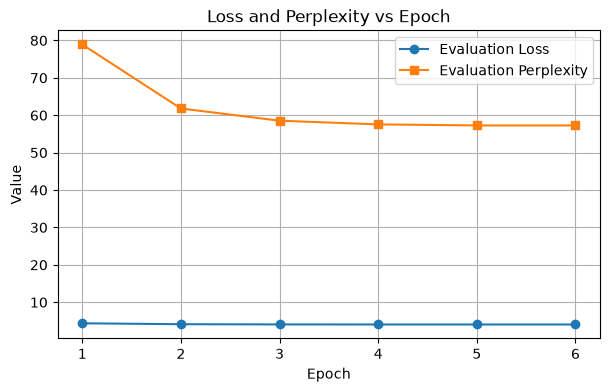

In [9]:
history = trainer.state.log_history

train_losses = [
    item["loss"] for item in history
    if "loss" in item and "eval_loss" not in item
]

eval_losses = [
    item["eval_loss"] for item in history
    if "eval_loss" in item
]

epochs = range(1, len(eval_losses) + 1)

eval_perplexities = [np.exp(loss) for loss in eval_losses]

plt.figure(figsize=(7, 4))
plt.plot(epochs, eval_losses, marker="o", label="Evaluation Loss")
plt.plot(epochs, eval_perplexities, marker="s", label="Evaluation Perplexity")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.title("Loss and Perplexity vs Epoch")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
def generate_text(prompt, temperature=0.8, top_k=50, top_p=0.95):
    model.eval()

    inputs = tokenizer(prompt, return_tensors="pt")

    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=60,
            do_sample=True,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            pad_token_id=tokenizer.eos_token_id
        )

    return tokenizer.decode(output[0], skip_special_tokens=True)


prompt = "Artificial intelligence"

print("Temperature 0.3:")
print(generate_text(prompt, temperature=0.3))

print("\nTemperature 0.8:")
print(generate_text(prompt, temperature=0.8))

print("\nTemperature 1.2:")
print(generate_text(prompt, temperature=1.2))

print("\nTop-k sampling:")
print(generate_text(prompt, temperature=0.8, top_k=20, top_p=1.0))

print("\nTop-p sampling:")
print(generate_text(prompt, temperature=0.8, top_k=0, top_p=0.9))

Temperature 0.3:
Artificial intelligence is a new field of artificial intelligence that uses machine learning to learn patterns. It uses machine learning to learn patterns. It uses machine learning to learn patterns. It uses machine learning to learn patterns. It uses machine learning to learn patterns. It uses machine learning to learn patterns. It uses machine learning to

Temperature 0.8:
Artificial intelligence and computer learning predict patterns based on human intelligence. In this article, we describe how artificial intelligence models and models predict patterns based on human intelligence. We discuss neural networks using human brain networks to learn neural networks. We explore neural networks using neural networks to learn neural networks. We analyze neural networks based on

Temperature 1.2:
Artificial intelligence uses human brain cells that use human data to create artificial algorithms.
















































Top-k sampling:
Artificial intellig